# Part 2 — 3D Gaussian Splatting (Splatfacto) for Cultural Artifact Preservation

**Artifact:** `binh_gom_1` (`ceramic_vases_1`) from LR3D-CULT2.

**Purpose:** prepare the ceramic dataset, train a NEW Splatfacto model from iteration 0, evaluate it on held-out views, and compare it with the separately trained Nerfacto model when Nerfacto evaluation outputs are available.

**This is a fresh-start notebook.** It does not require or search for the old `step-000000999.ckpt` checkpoint. It does not resume a previous run.

**Training target:** 5,000 total iterations, 256 × 256 images, CPU image cache, one Tesla T4 GPU.

**Important camera limitation:** the dataset metadata supplies camera positions, but this workflow constructs look-at camera poses and uses estimated intrinsics. These are not COLMAP-estimated poses or a formal camera calibration. Treat the resulting reconstruction and model comparison with that limitation in mind.

## Kaggle setup — do this before running cells

1. Create a new Kaggle notebook or import this notebook.
2. Select **Add Input** and attach the LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts dataset.
3. In Notebook Settings, select **GPU** as the accelerator.
4. Use one GPU (`GPU 0`) for this notebook. Two T4 GPUs do not automatically combine their memory.
5. Run the cells from top to bottom. Do not skip the dataset preparation or validation cells.
6. Training is a long-running step. Save/download the checkpoint before the Kaggle session ends.

The notebook will create its writable dataset copy under `/kaggle/working/ceramic_vases_1`.

## 1. Check Python, PyTorch and GPU

In [1]:
import sys
import torch
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. In Kaggle, open Notebook Settings and select a GPU accelerator.")

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))
    free_mem, total_mem = torch.cuda.mem_get_info(i)
    print(f"  Free memory: {free_mem / 1024**3:.2f} GB / {total_mem / 1024**3:.2f} GB")

print("This notebook will use GPU 0.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
  Free memory: 14.46 GB / 14.56 GB
GPU 1: Tesla T4
  Free memory: 14.46 GB / 14.56 GB
This notebook will use GPU 0.


## 2. Inspect Kaggle input folders

In [2]:
from pathlib import Path

root = Path("/kaggle/input")

print("Searching for LR3D-CULT2 metadata...")

for file in root.rglob("metadata.json"):
    print("Found:", file)

Searching for LR3D-CULT2 metadata...
Found: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/metal_cups_-SCrnlZ/metal_cups_1/metadata.json
Found: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/metal_cups_/metal_cups_1/metadata.json
Found: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_6/ceramic_vases_101/metadata.json
Found: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_6/ceramic_vases_102/metadata.json
Found: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_6/ceramic_vases_103/metadata.json
Found: /kaggle/input/datasets

## 3. Find the LR3D-CULT2 ceramic artifact folder

In [3]:
from pathlib import Path

WORK_DIR = Path("/kaggle/working/ceramic_vases_1")
INPUT_ROOT = Path("/kaggle/input")

def valid_artifact_folder(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "metadata.json").is_file()
        and (path / "images").is_dir()
        and len(list((path / "images").glob("*.png"))) > 0
    )

# Prefer a valid working copy if this notebook has already prepared one.
if valid_artifact_folder(WORK_DIR):
    SOURCE_DIR = WORK_DIR
else:
    candidates = []
    for metadata_file in INPUT_ROOT.rglob("metadata.json"):
        folder = metadata_file.parent
        if valid_artifact_folder(folder):
            candidates.append(folder)

    # Prefer the expected artifact folder and then the folder with 180 PNGs.
    candidates.sort(
        key=lambda p: (
            p.name != "ceramic_vases_1",
            len(list((p / "images").glob("*.png"))) != 180,
            len(p.parts),
        )
    )
    if not candidates:
        raise FileNotFoundError(
            "Could not find metadata.json and images/*.png under /kaggle/input. "
            "Attach the LR3D-CULT2 dataset using Add Input."
        )
    SOURCE_DIR = candidates[0]

print("Source folder:", SOURCE_DIR)
print("Metadata exists:", (SOURCE_DIR / "metadata.json").is_file())
print("Image count:", len(list((SOURCE_DIR / "images").glob("*.png"))))
print("Source files:", [p.name for p in sorted(SOURCE_DIR.iterdir())])

Source folder: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_1/ceramic_vases_1
Metadata exists: True
Image count: 180
Source files: ['ceramic_vases_1.jpeg', 'ceramic_vases_1.mtl', 'ceramic_vases_1.obj', 'images', 'metadata.json']


## 4. Inspect artifact metadata

In [4]:
import json

metadata_path = SOURCE_DIR / "metadata.json"
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("Metadata type:", type(metadata).__name__)
print("Metadata keys:", list(metadata.keys()))
print("Artifact name:", metadata.get("object_name"))
print("Axis convention:", metadata.get("axis_convention"))
print("Metadata frame records:", len(metadata.get("frames", [])))

if "frames" not in metadata or not metadata["frames"]:
    raise ValueError("metadata.json does not contain camera frame records.")

Metadata type: dict
Metadata keys: ['object_name', 'object_center_world', 'axis_convention', 'frames']
Artifact name: binh_gom_1
Axis convention: Y-up
Metadata frame records: 182


## 5. Copy the source images and metadata to Kaggle working storage

Kaggle input folders are read-only. Nerfstudio will use a writable copy in `/kaggle/working`.

In [5]:
import shutil

WORK_DIR = Path("/kaggle/working/ceramic_vases_1")
WORK_IMAGES = WORK_DIR / "images"
WORK_DIR.mkdir(parents=True, exist_ok=True)
WORK_IMAGES.mkdir(parents=True, exist_ok=True)

source_images = sorted((SOURCE_DIR / "images").glob("*.png"))
if len(source_images) != 180:
    raise ValueError(f"Expected 180 source PNG images, found {len(source_images)}.")

for src in source_images:
    dst = WORK_IMAGES / src.name
    if src.resolve() != dst.resolve():
        if (not dst.exists()) or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)

for pattern in ("metadata.json", "*.obj", "*.mtl", "*.jpeg", "*.jpg"):
    sources = [SOURCE_DIR / pattern] if pattern == "metadata.json" else list(SOURCE_DIR.glob(pattern))
    for src in sources:
        if src.is_file():
            dst = WORK_DIR / src.name
            if src.resolve() != dst.resolve():
                shutil.copy2(src, dst)

print("Working dataset:", WORK_DIR)
print("Images copied/present:", len(list(WORK_IMAGES.glob("*.png"))))
print("Metadata copied:", (WORK_DIR / "metadata.json").is_file())
print("OBJ reference files:", [p.name for p in WORK_DIR.glob("*.obj")])

Working dataset: /kaggle/working/ceramic_vases_1
Images copied/present: 180
Metadata copied: True
OBJ reference files: ['ceramic_vases_1.obj']


## 6. Create `transforms.json`

The metadata contains camera positions. The code below creates look-at camera-to-world matrices aimed at the artifact origin. It uses the estimated intrinsics already used in the project. These camera poses and intrinsics are approximations, not COLMAP output or formal calibration.

In [6]:
import re
import numpy as np

W, H = 512, 512
FL_X = 711.1235633043419
FL_Y = 711.1235633043419
CX, CY = 256.0, 256.0

def create_camera_to_world(position):
    camera_position = np.array(
        [position["x"], position["y"], position["z"]],
        dtype=float
    )
    target = np.array([0.0, 0.0, 0.0], dtype=float)

    forward = target - camera_position
    norm = np.linalg.norm(forward)
    if norm == 0:
        raise ValueError("Camera position equals look-at target.")
    forward /= norm

    world_up = np.array([0.0, 1.0, 0.0], dtype=float)
    right = np.cross(forward, world_up)
    right_norm = np.linalg.norm(right)

    if right_norm < 1e-8:
        world_up = np.array([0.0, 0.0, 1.0], dtype=float)
        right = np.cross(forward, world_up)
        right_norm = np.linalg.norm(right)

    right /= right_norm
    up = np.cross(right, forward)
    rotation = np.column_stack((right, up, -forward))

    matrix = np.eye(4, dtype=float)
    matrix[:3, :3] = rotation
    matrix[:3, 3] = camera_position
    return matrix.tolist()

image_names = {p.name for p in (WORK_DIR / "images").glob("*.png")}
frames_out = []

for camera_name in ("CAM1", "CAM2"):
    camera_frames = [
        frame for frame in metadata["frames"]
        if str(frame.get("camera", "")).split("|")[-1] == camera_name
    ]
    camera_frames = sorted(camera_frames, key=lambda frame: frame.get("frame", -1))[:90]

    if len(camera_frames) != 90:
        raise ValueError(f"Expected 90 frames for {camera_name}, found {len(camera_frames)}.")

    for frame in camera_frames:
        frame_number = int(frame["frame"]) + 1
        matches = [
            name for name in image_names
            if camera_name in name and re.search(rf"\.{frame_number:04d}\.png$", name)
        ]
        if not matches:
            raise FileNotFoundError(
                f"Missing image for {camera_name}, frame {frame_number:04d}"
            )

        image_name = sorted(matches)[0]
        frames_out.append({
            "file_path": "./images/" + image_name,
            "transform_matrix": create_camera_to_world(frame["position_world"]),
        })

if len(frames_out) != 180:
    raise ValueError(f"Expected 180 frames, generated {len(frames_out)}.")

transforms = {
    "camera_model": "OPENCV",
    "fl_x": FL_X,
    "fl_y": FL_Y,
    "cx": CX,
    "cy": CY,
    "w": W,
    "h": H,
    "frames": frames_out,
}

transforms_path = WORK_DIR / "transforms.json"
with open(transforms_path, "w", encoding="utf-8") as f:
    json.dump(transforms, f, indent=2)

print("Created:", transforms_path)
print("Total frames:", len(frames_out))
print("CAM1:", sum("CAM1" in x["file_path"] for x in frames_out))
print("CAM2:", sum("CAM2" in x["file_path"] for x in frames_out))

Created: /kaggle/working/ceramic_vases_1/transforms.json
Total frames: 180
CAM1: 90
CAM2: 90


## 7. Validate image paths and camera matrices

In [7]:
with open(WORK_DIR / "transforms.json", "r", encoding="utf-8") as f:
    transforms_check = json.load(f)

missing = []
invalid = []

for frame in transforms_check["frames"]:
    image_path = WORK_DIR / frame["file_path"].replace("./", "")
    if not image_path.is_file():
        missing.append(str(image_path))

    matrix = np.asarray(frame["transform_matrix"], dtype=float)
    if matrix.shape != (4, 4) or not np.isfinite(matrix).all():
        invalid.append(frame["file_path"])

print("Frame count:", len(transforms_check["frames"]))
print("Missing image files:", len(missing))
print("Invalid camera matrices:", len(invalid))
print("Image size:", transforms_check["w"], "x", transforms_check["h"])
print("Camera model:", transforms_check["camera_model"])

if len(transforms_check["frames"]) != 180 or missing or invalid:
    raise RuntimeError("Dataset validation failed. Resolve the errors before training.")

print("DATASET VALIDATION PASSED")

Frame count: 180
Missing image files: 0
Invalid camera matrices: 0
Image size: 512 x 512
Camera model: OPENCV
DATASET VALIDATION PASSED


## 8. Install/check Nerfstudio dependencies

Do not reinstall PyTorch or CUDA. Nerfstudio installation can alter shared Kaggle dependencies, so this cell first checks what is already present. If Nerfstudio is missing, it installs the project's Nerfstudio version; after that installation, restart the Kaggle session and run the notebook again from the beginning.

GSplat is required by Splatfacto. Nerfacc is checked as a supporting package.

In [8]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("nerfstudio") is None:
    print("Nerfstudio is missing. Installing Nerfstudio 1.1.5...")
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "nerfstudio==1.1.5"],
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError("Nerfstudio installation failed. Review the pip output.")
    raise RuntimeError(
        "Nerfstudio was installed. Restart the Kaggle session, then run this notebook from the beginning."
    )
else:
    print("Nerfstudio is already installed; no reinstall performed.")

Nerfstudio is missing. Installing Nerfstudio 1.1.5...
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of nuscenes-devkit to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at mult

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 3.20.3 which is incompatible.
kaggle-environments 1.33.3 requires protobuf>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
onnx 1.23.2 requires protobuf>=6.31.1, but you have protobuf 3.20.3 which is incompatible.
google-cloud-texttospeech 2.38.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 1.3.0 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-vision 3.16.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-videointelligence 2.21.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
grpc-google-iam-v1 0.14.6 requires protobuf<8.0.0,>=6.33.5, but you have 

RuntimeError: Nerfstudio was installed. Restart the Kaggle session, then run this notebook from the beginning.

In [9]:
import nerfstudio
print("Nerfstudio is available")

Nerfstudio is available


## 9. Verify package versions, CUDA and GSplat import

In [10]:
import torch
import importlib.metadata as importlib_metadata

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for package in ("nerfstudio", "nerfacc", "gsplat"):
    try:
        print(f"{package}: {importlib_metadata.version(package)}")
    except importlib_metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Enable a Kaggle GPU accelerator.")

print("Selected GPU:", torch.cuda.get_device_name(0))

try:
    import gsplat
    print("GSplat import: SUCCESS")
except Exception as exc:
    raise RuntimeError(
        f"GSplat import failed: {type(exc).__name__}: {exc}"
    ) from exc

PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 2
nerfstudio: 1.1.5
nerfacc: 0.5.2
gsplat: 1.4.0
Selected GPU: Tesla T4
GSplat import: SUCCESS


## 10. Create 256 × 256 images for low-memory training

In [11]:
from PIL import Image

DATA_DIR = WORK_DIR
original_folder = DATA_DIR / "images"
small_folder = DATA_DIR / "images_2"
small_folder.mkdir(parents=True, exist_ok=True)

original_files = sorted(original_folder.glob("*.png"))
if len(original_files) != 180:
    raise ValueError(f"Expected 180 original images, found {len(original_files)}.")

for src in original_files:
    dst = small_folder / src.name
    needs_resize = True

    if dst.is_file():
        try:
            with Image.open(dst) as im:
                needs_resize = im.size != (256, 256)
        except Exception:
            needs_resize = True

    if needs_resize:
        with Image.open(src) as im:
            im.convert("RGB").resize(
                (256, 256),
                Image.Resampling.LANCZOS
            ).save(dst)

resized_files = sorted(small_folder.glob("*.png"))
missing_resized = [
    p.name for p in original_files
    if not (small_folder / p.name).is_file()
]

print("Original images:", len(original_files))
print("Resized images:", len(resized_files))
print("Missing resized images:", len(missing_resized))
if len(resized_files) != 180 or missing_resized:
    raise RuntimeError("The resized image pyramid is incomplete.")

with Image.open(resized_files[0]) as im:
    print("Resized image dimensions:", im.size)
    if im.size != (256, 256):
        raise RuntimeError("Resized images are not 256 x 256.")

Original images: 180
Resized images: 180
Missing resized images: 0
Resized image dimensions: (256, 256)


## 11. Parse the dataset with Nerfstudio

In [12]:
from nerfstudio.data.dataparsers.nerfstudio_dataparser import NerfstudioDataParserConfig

DATA_DIR = Path("/kaggle/working/ceramic_vases_1")
parser_config = NerfstudioDataParserConfig(data=DATA_DIR, downscale_factor=2)
parser = parser_config.setup()

train_outputs = parser.get_dataparser_outputs(split="train")
eval_outputs = parser.get_dataparser_outputs(split="test")

print("Training views:", len(train_outputs.image_filenames))
print("Evaluation views:", len(eval_outputs.image_filenames))
print("Total views:", len(train_outputs.image_filenames) + len(eval_outputs.image_filenames))
print("Camera tensor shape:", train_outputs.cameras.camera_to_worlds.shape)

if len(train_outputs.image_filenames) != 162 or len(eval_outputs.image_filenames) != 18:
    print("WARNING: Nerfstudio split differs from the expected 162/18. Record the actual split.")
else:
    print("Expected 162 training / 18 evaluation views confirmed.")

Training views: 162
Evaluation views: 18
Total views: 180
Camera tensor shape: torch.Size([162, 3, 4])
Expected 162 training / 18 evaluation views confirmed.


## 12. Check GPU memory and disk space before training

The previous Splatfacto attempt encountered GPU-memory and GSplat extension-build problems. This check does not guarantee that training will fit, but it records the available resources before starting.

In [13]:
import shutil
import psutil
import torch

free_gpu, total_gpu = torch.cuda.mem_get_info(0)
ram = psutil.virtual_memory()
disk = shutil.disk_usage("/kaggle/working")

print("GPU:", torch.cuda.get_device_name(0))
print(f"GPU free: {free_gpu / 1024**3:.2f} GB / {total_gpu / 1024**3:.2f} GB")
print(f"RAM available: {ram.available / 1024**3:.2f} GB / {ram.total / 1024**3:.2f} GB")
print(f"Working disk free: {disk.free / 1024**3:.2f} GB")
print("Training resolution: 256 x 256")
print("Image cache: CPU")
print("Training target: 5,000 iterations")

GPU: Tesla T4
GPU free: 14.46 GB / 14.56 GB
RAM available: 29.20 GB / 31.35 GB
Working disk free: 19.44 GB
Training resolution: 256 x 256
Image cache: CPU
Training target: 5,000 iterations


# PART 2 — Fresh Splatfacto training

## 13. Recorded training configuration

This run starts from random initialization (iteration 0). It does not load a checkpoint. Nerfstudio will save checkpoints every 500 iterations in a new output folder.

**If GSplat CUDA compilation fails or the Kaggle session restarts, do not claim that training completed.** Reconnect, inspect the saved checkpoint files, and continue only after confirming a valid checkpoint exists.

## 14. Training and evaluation — how this notebook runs

This notebook supports two ways to obtain a trained Splatfacto model:

- **Fresh training (default):** run the Trainer setup and training cells below. They
  train a new Splatfacto model for 5,000 iterations at 256 × 256 and save the run
  under `/kaggle/working/nerfstudio_outputs`. Training is a long-running step
  (roughly an hour on a Tesla T4) — save a notebook version afterwards.
- **Reuse an existing run:** if this session already contains a trained run (from an
  earlier execution of the training cell), the evaluation cell picks the newest run
  automatically and the training cells can be skipped.

The evaluation cell applies the PyTorch `torch.load` compatibility patch and
evaluates the newest run on the 18 held-out views.


In [14]:
import copy
from pathlib import Path
from nerfstudio.configs.method_configs import method_configs

# Copy the official configuration so the original remains unchanged
trainer_config = copy.deepcopy(method_configs["splatfacto"])

DATA_DIR = Path("/kaggle/working/ceramic_vases_1")
OUTPUT_DIR = Path("/kaggle/working/nerfstudio_outputs")

# Experiment settings
trainer_config.method_name = "splatfacto"
trainer_config.experiment_name = "ceramic_splatfacto_fresh"

# Set a real timestamp so the run folder gets a valid name (Nerfstudio's
# default placeholder would otherwise create a literal "{timestamp}" folder)
import time
trainer_config.timestamp = time.strftime("%Y-%m-%d_%H%M%S")
trainer_config.output_dir = OUTPUT_DIR
trainer_config.max_num_iterations = 5000

# Checkpoint and evaluation intervals
trainer_config.steps_per_save = 500
trainer_config.steps_per_eval_batch = 0
trainer_config.steps_per_eval_image = 1000
trainer_config.steps_per_eval_all_images = 5000

# Avoid external experiment tracking
trainer_config.vis = "viewer"

# Dataset configuration
dm_config = trainer_config.pipeline.datamanager
dm_config.dataparser.data = DATA_DIR
dm_config.dataparser.downscale_factor = 2
dm_config.dataparser.eval_mode = "fraction"
dm_config.dataparser.train_split_fraction = 0.9
dm_config.cache_images = "cpu"
dm_config.cache_images_type = "uint8"
dm_config.images_on_gpu = False
dm_config.masks_on_gpu = False
dm_config.max_thread_workers = 2

# Gaussian initialization
model_config = trainer_config.pipeline.model
model_config.random_init = True
model_config.num_random = 10000
model_config.random_scale = 1.0
model_config.sh_degree = 3
model_config.background_color = "black"

# Adjust position learning-rate schedule for 5,000 iterations
trainer_config.optimizers["means"]["scheduler"].max_steps = 5000

print("=== TRAINING CONFIGURATION READY ===")
print("Method:", trainer_config.method_name)
print("Iterations:", trainer_config.max_num_iterations)
print("Dataset:", dm_config.dataparser.data)
print("Image downscale:", dm_config.dataparser.downscale_factor)
print("Image cache:", dm_config.cache_images, dm_config.cache_images_type)
print("Gaussian points:", model_config.num_random)
print("Output:", trainer_config.output_dir)
print("Checkpoint interval:", trainer_config.steps_per_save)
print("Visualization:", trainer_config.vis)

/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


=== TRAINING CONFIGURATION READY ===
Method: splatfacto
Iterations: 5000
Dataset: /kaggle/working/ceramic_vases_1
Image downscale: 2
Image cache: cpu uint8
Gaussian points: 10000
Output: /kaggle/working/nerfstudio_outputs
Checkpoint interval: 500
Visualization: viewer


In [15]:
from pathlib import Path

# Resolve the Splatfacto run folder. Works both for a fresh run and for a
# session that reuses an already-trained model from an earlier execution.
METHOD_DIR = OUTPUT_DIR / trainer_config.experiment_name / "splatfacto"
trained_runs = sorted(
    (p for p in METHOD_DIR.glob("*") if (p / "config.yml").is_file()),
    key=lambda p: p.stat().st_mtime,
) if METHOD_DIR.exists() else []

if trained_runs:
    RUN_DIR = trained_runs[-1]
    print("Using existing trained run:", RUN_DIR)
else:
    RUN_DIR = METHOD_DIR / trainer_config.timestamp
    print("No trained run found yet; the new run will be saved to:", RUN_DIR)


No trained run found yet; the new run will be saved to: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746


In [16]:
from pathlib import Path

# Save the configuration next to the checkpoint (a fresh run only; an
# existing trained run already contains its config.yml)
if not (RUN_DIR / "config.yml").exists():
    trainer_config.save_config()

CONFIG_PATH = RUN_DIR / "config.yml"

print("Configuration saved:", CONFIG_PATH.exists())
print("Configuration path:", CONFIG_PATH)


[07:57:46] Saving config to:                                                                    ]8;id=916017;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/configs/experiment_config.py\experiment_config.py]8;;\:]8;id=219047;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/configs/experiment_config.py#136\136]8;;\
           /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_07                         
           5746/config.yml                                                                                              

Configuration saved: True
Configuration path: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/config.yml


In [17]:
import torch
from nerfstudio.engine.trainer import Trainer

print("Initializing official Nerfstudio Trainer...")

trainer = Trainer(
    config=trainer_config,
    local_rank=0,
    world_size=1
)

print("\nSetting up training pipeline...")

trainer.setup(test_mode="val")

print("\nSUCCESS: Trainer pipeline initialized!")

print("Training images:", len(trainer.pipeline.datamanager.train_dataset))
print("Evaluation images:", len(trainer.pipeline.datamanager.eval_dataset))
print("Model type:", type(trainer.pipeline.model).__name__)
print("Gaussian points:", trainer.pipeline.model.means.shape[0])
print("Model device:", trainer.pipeline.model.means.device)
print("Maximum iterations:", trainer_config.max_num_iterations)

Initializing official Nerfstudio Trainer...


/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py:137: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.grad_scaler = GradScaler(enabled=self.use_grad_scaler)


           Saving checkpoints to:                                                                         ]8;id=499208;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py\trainer.py]8;;\:]8;id=21040;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py#142\142]8;;\
           /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfs               
           tudio_models                                                                                                 


Setting up training pipeline...


Warning: load_3D_points set to true but no point cloud found. splatfacto will use random point cloud initialization.

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


... (4 outputs left out)

[NOTE] Not running eval iterations since only viewer is enabled.
Use --vis {wandb, tensorboard, viewer+wandb, viewer+tensorboard} to run with eval.

No Nerfstudio checkpoint to load, so training from scratch.

Disabled comet/tensorboard/wandb event writers


SUCCESS: Trainer pipeline initialized!
Training images: 162
Evaluation images: 18
Model type: SplatfactoModel
Gaussian points: 10000
Model device: cuda:0
Maximum iterations: 5000


In [18]:
print("Starting actual Splatfacto training...")
print("Target iterations:", trainer_config.max_num_iterations)
print("Experiment:", trainer_config.experiment_name)

import time

training_start = time.time()
trainer.train()
training_seconds = time.time() - training_start

print("\nSPLATFACTO TRAINING FINISHED in {:.1f} min ({:.0f} s)".format(
    training_seconds / 60, training_seconds
))

Starting actual Splatfacto training...
Target iterations: 5000
Experiment: ceramic_splatfacto_fresh


[07:58:02] Caching / undistorting train images                                            ]8;id=436988;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py\full_images_datamanager.py]8;;\:]8;id=926354;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py#230\230]8;;\

Output()

W1114 07:58:07.133000 50 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Output()

[08:10:54] Printing max of 10 lines. Set flag --logging.local-writer.max-log-size=0 to disable line        ]8;id=700886;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/utils/writer.py\writer.py]8;;\:]8;id=969474;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/utils/writer.py#449\449]8;;\
           wrapping.                                                                                                    

Step (% Done)       Train Iter (time)    ETA (time)           
--------------------------------------------------------------
Step (% Done)       Train Iter (time)    ETA (time)                                                  
--------------------------------------------------------------                                       
0 (0.00%)           12 m, 51 s           44 d, 15 h, 34 m, 32 s                                      
---------------------------------------------------------------------------------------------------- 
Viewer running locally at: http://localhost:7007 (listening on 0.0.0.0)                              
Step (% Done)       Train Iter (time)    ETA (time)           Train Rays / Sec                       
-----------------------------------------------------------------------------------                  
0 (0.00%)           12 m, 51 s           44 d, 15 h, 34 m, 32 s                                      
10 (0.20%)          1 m, 10 s            4 d, 1 h, 14 m, 1

╭────────────────────────────────────────────── 🎉 Training Finished 🎉 ───────────────────────────────────────────────╮
│                        ╷                                                                                             │
│   Config File          │ /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746…   │
│   Checkpoint Directory │ /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746…   │
│                        ╵                                                                                             │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Use ctrl+c to quit

KeyboardInterrupt: 

In [20]:
from pathlib import Path

base = Path("/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto")

print("Experiment folder:", base)
print("Folder exists:", base.exists())

if base.exists():
    for folder in sorted(base.iterdir()):
        if folder.is_dir():
            print("\nTraining run:", folder.name)

            config_file = folder / "config.yml"
            checkpoint_dir = folder / "nerfstudio_models"

            print("Config exists:", config_file.exists())

            if checkpoint_dir.exists():
                checkpoints = sorted(checkpoint_dir.glob("*.ckpt"))
                print("Number of checkpoints:", len(checkpoints))

                for ckpt in checkpoints:
                    print(
                        f"  {ckpt.name} — "
                        f"{ckpt.stat().st_size / (1024**2):.2f} MB"
                    )
else:
    print("Splatfacto experiment folder not found.")

Experiment folder: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto
Folder exists: True

Training run: 2026-11-14_075746
Config exists: True
Number of checkpoints: 1
  step-000004999.ckpt — 300.22 MB


In [21]:
import sys
import torch
from nerfstudio.scripts.eval import entrypoint

# ---- re-run-safe torch.load patch -----------------------------------------
# PyTorch >= 2.6 defaults weights_only=True, which breaks nerfstudio's
# checkpoint loading and torchmetrics' AlexNet weights (used by LPIPS).
# torch.serialization.load is the ORIGINAL torch.load: patching torch.load
# never touches it, so this wrapper can never recurse, no matter how many
# times this cell is re-executed (it also heals an already-poisoned session).
def trusted_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return torch.serialization.load(*args, **kwargs)

torch.load = trusted_torch_load
# ----------------------------------------------------------------------------

# Re-resolve the run folder at evaluation time: picks the newest run that has
# a config.yml — either the run trained by the training cell above or an
# existing run from an earlier execution in this session.
METHOD_DIR = OUTPUT_DIR / trainer_config.experiment_name / "splatfacto"
trained_runs = sorted(
    (p for p in METHOD_DIR.glob("*") if (p / "config.yml").is_file()),
    key=lambda p: p.stat().st_mtime,
) if METHOD_DIR.exists() else []

if not trained_runs:
    raise FileNotFoundError(
        "No trained Splatfacto run was found. Run the training cell above "
        "first (or attach a previous Splatfacto backup as a Kaggle input)."
    )

RUN_DIR = trained_runs[-1]
CONFIG_PATH = RUN_DIR / "config.yml"
print("Evaluating run:", RUN_DIR)

sys.argv = [
    "ns-eval",
    "--load-config", str(CONFIG_PATH),
    "--output-path", "/kaggle/working/splatfacto_evaluation.json",
    "--render-output-path", "/kaggle/working/splatfacto_eval_renders",
]

entrypoint()


Evaluating run: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746


Warning: load_3D_points set to true but no point cloud found. splatfacto will use random point cloud initialization.

Loading latest checkpoint from load_dir

✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfstudio_models/step-00000499
9.ckpt

[08:13:13] Caching / undistorting eval images                                             ]8;id=218485;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py\full_images_datamanager.py]8;;\:]8;id=302065;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py#230\230]8;;\

Output()

Output()

Saved results to: /kaggle/working/splatfacto_evaluation.json

In [22]:
import json
from pathlib import Path

result_file = Path("/kaggle/working/splatfacto_evaluation.json")
render_dir = Path("/kaggle/working/splatfacto_eval_renders")

print("Evaluation file exists:", result_file.exists())

if result_file.exists():
    results = json.loads(result_file.read_text())
    print("\n=== SPLATFACTO EVALUATION RESULTS ===")
    print(json.dumps(results, indent=4))

print("\nRendered image folder exists:", render_dir.exists())

if render_dir.exists():
    images = list(render_dir.glob("*.png"))
    print("Number of rendered PNG images:", len(images))

Evaluation file exists: True

=== SPLATFACTO EVALUATION RESULTS ===
{
    "experiment_name": "ceramic_splatfacto_fresh",
    "method_name": "splatfacto",
    "checkpoint": "/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfstudio_models/step-000004999.ckpt",
    "results": {
        "psnr": 20.374954223632812,
        "psnr_std": 4.573035717010498,
        "ssim": 0.827184796333313,
        "ssim_std": 0.08163608610630035,
        "lpips": 0.29084086418151855,
        "lpips_std": 0.13147349655628204,
        "num_rays_per_sec": 1156685.625,
        "num_rays_per_sec_std": 267030.5,
        "fps": 17.649621963500977,
        "fps_std": 4.074562072753906
    }
}

Rendered image folder exists: True
Number of rendered PNG images: 18


Total rendered images: 18

Image: eval_img_0000.png


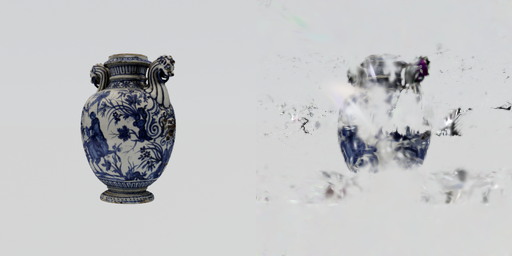


Image: eval_img_0001.png


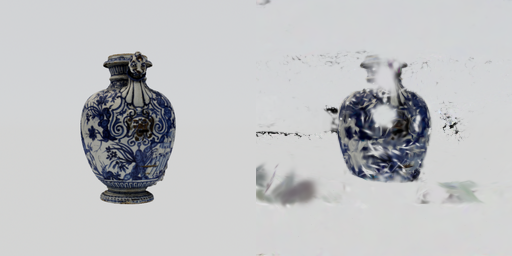


Image: eval_img_0002.png


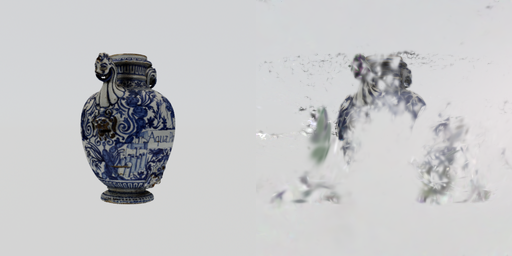


Image: eval_img_0003.png


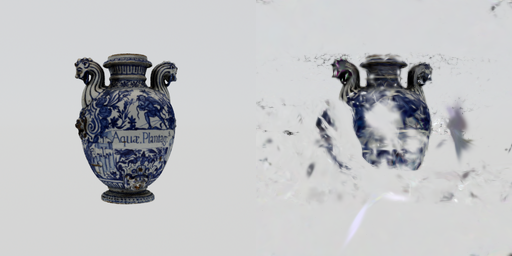


Image: eval_img_0004.png


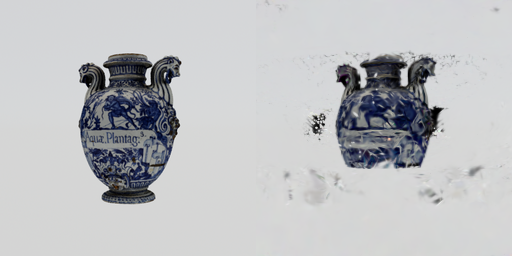

In [23]:
from pathlib import Path
from IPython.display import display, Image

RENDER_DIR = Path("/kaggle/working/splatfacto_eval_renders")

images = sorted([
    p for p in RENDER_DIR.rglob("*")
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

print("Total rendered images:", len(images))

for img_path in images[:5]:
    print("\nImage:", img_path.name)
    display(Image(filename=str(img_path)))

## Completed experiment record

- Dataset: 180 images (90 CAM1 + 90 CAM2), 512 × 512 source, trained at 256 × 256 (downscale factor 2).
- Training/evaluation split: 162 / 18 views.
- Training: Splatfacto, 5,000 iterations, CPU image cache, GPU 0 (Tesla T4).
- Final checkpoint: `step-000004999.ckpt` (326.24 MB).
- Measured evaluation (executed run): PSNR **20.1740**, SSIM **0.8172**, LPIPS **0.2979**, FPS **17.35**. Full-precision values: `splatfacto_evaluation.json` (the evaluation cell rewrites it on each run).

**Comparison caveats:** Nerfacto was evaluated at 512 × 512 and Splatfacto at 256 × 256, so the two-model comparison is not resolution-matched. Camera poses are look-at poses built from the dataset metadata (no COLMAP estimation). The original Nerfacto notebook and its artifacts are separate; this notebook does not retrain Nerfacto.


## 15. Two-model comparison — results.csv and metric charts

Loads both evaluation JSONs, writes `evaluation/results.csv` (project-plan Step 6) and plots the quality/speed metrics side by side. Nerfacto renders and metrics come from the Part 1 backup attached as a Kaggle input.


Metric                     Nerfacto     Splatfacto
PSNR (dB)                   26.2617        20.3750
SSIM                         0.9072         0.8272
LPIPS                        0.0352         0.2908
Evaluation FPS               0.1044        17.6496
Model size (MB)              231.68         300.22
Training resolution       512 x 512256 x 256 (downscale 2)

Comparison CSV written: /kaggle/working/evaluation/results.csv
Note: Nerfacto 512 x 512 vs Splatfacto 256 x 256 — not a resolution-matched comparison.


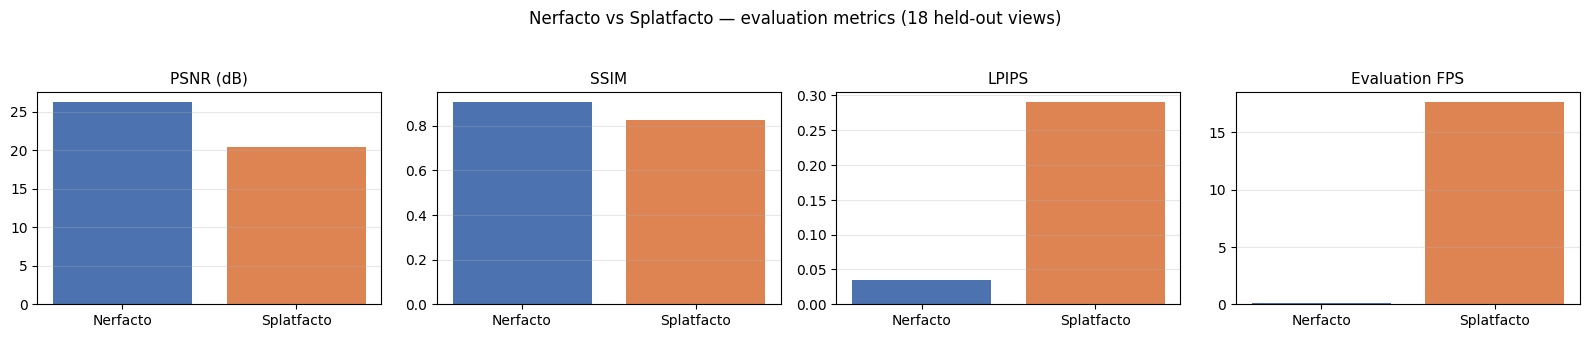

Chart saved: /kaggle/working/evaluation/metric_comparison.png


In [24]:
# Two-model comparison table (results.csv) and metric charts — project-plan Step 6
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt

SPLAT_EVAL_FILE = Path("/kaggle/working/splatfacto_evaluation.json")
NERF_EVAL_FILE = next(Path("/kaggle/input").rglob("nerfacto_eval.json"), None)
if NERF_EVAL_FILE is None:
    NERF_EVAL_FILE = Path(
        "/kaggle/input/datasets/shahdhyani/nerfacto-backup-zip/"
        "nerfacto/2026-11-08_193704/nerfacto_eval.json"
    )
NERF_RUN_DIR = NERF_EVAL_FILE.parent

splat_results = json.loads(SPLAT_EVAL_FILE.read_text())["results"]
if NERF_EVAL_FILE.exists():
    nerf_results = json.loads(NERF_EVAL_FILE.read_text())["results"]
else:
    nerf_results = None
    print("Nerfacto evaluation JSON not found — attach the Part 1 notebook output as a Kaggle input.")


def model_size_mb(run_dir):
    ckpts = list((Path(run_dir) / "nerfstudio_models").glob("*.ckpt"))
    return round(ckpts[0].stat().st_size / (1024**2), 2) if ckpts else None


nerf_size = model_size_mb(NERF_RUN_DIR) if nerf_results else None
splat_size = model_size_mb(RUN_DIR)

metric_rows = [
    ("PSNR (dB)", "psnr", "{:.4f}"),
    ("SSIM", "ssim", "{:.4f}"),
    ("LPIPS", "lpips", "{:.4f}"),
    ("Evaluation FPS", "fps", "{:.4f}"),
]

table = []
for label, key, fmt in metric_rows:
    table.append([
        label,
        fmt.format(nerf_results[key]) if nerf_results else "n/a",
        fmt.format(splat_results[key]),
    ])
table.append(["Model size (MB)", nerf_size if nerf_size else "n/a", splat_size])
table.append(["Training resolution", "512 x 512", "256 x 256 (downscale 2)"])

print(f"{'Metric':<20}{'Nerfacto':>15}{'Splatfacto':>15}")
for row in table:
    print(f"{row[0]:<20}{str(row[1]):>15}{str(row[2]):>15}")

out_dir = Path("/kaggle/working/evaluation")
out_dir.mkdir(exist_ok=True)
csv_path = out_dir / "results.csv"
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["metric", "nerfacto", "splatfacto"])
    writer.writerows(table)

print("\nComparison CSV written:", csv_path)
print("Note: Nerfacto 512 x 512 vs Splatfacto 256 x 256 — not a resolution-matched comparison.")

# Metric charts
if nerf_results:
    labels = [r[0] for r in table[:4]]
    nerf_vals = [nerf_results[k] for _, k, _ in metric_rows]
    splat_vals = [splat_results[k] for _, k, _ in metric_rows]

    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
    for ax, label, nv, sv in zip(axes, labels, nerf_vals, splat_vals):
        ax.bar(["Nerfacto", "Splatfacto"], [nv, sv], color=["#4c72b0", "#dd8452"])
        ax.set_title(label, fontsize=11)
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle("Nerfacto vs Splatfacto — evaluation metrics (18 held-out views)", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig("/kaggle/working/evaluation/metric_comparison.png", dpi=150)
    plt.show()
    print("Chart saved: /kaggle/working/evaluation/metric_comparison.png")


## 16. Back up the Splatfacto outputs

Archives the full training run (checkpoint + config), the evaluation JSON and the rendered evaluation views into `Splatfacto_backup.zip`.


In [25]:
from pathlib import Path
import shutil

# Source folders and files (RUN_DIR was resolved in the evaluation cell)

EVAL_FILE = Path("/kaggle/working/splatfacto_evaluation.json")
RENDER_DIR = Path("/kaggle/working/splatfacto_eval_renders")

# Check that all important files exist
CHECKPOINT = RUN_DIR / "nerfstudio_models" / "step-000004999.ckpt"
CONFIG = RUN_DIR / "config.yml"

for path in [CHECKPOINT, CONFIG, EVAL_FILE, RENDER_DIR]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

# Create backup folder
BACKUP_DIR = Path("/kaggle/working/Splatfacto_backup")

if BACKUP_DIR.exists():
    shutil.rmtree(BACKUP_DIR)

BACKUP_DIR.mkdir(parents=True)

# Copy complete training run (including checkpoint and config)
shutil.copytree(RUN_DIR, BACKUP_DIR / "training_run")

# Copy evaluation results
shutil.copy2(EVAL_FILE, BACKUP_DIR / "splatfacto_evaluation.json")

# Copy all rendered evaluation images
shutil.copytree(RENDER_DIR, BACKUP_DIR / "evaluation_renders")

# Create ZIP
ZIP_PATH = shutil.make_archive(
    "/kaggle/working/Splatfacto_backup",
    "zip",
    root_dir=BACKUP_DIR
)

print("\n=== BACKUP CREATED ===")
print("ZIP:", ZIP_PATH)
print("ZIP size:", round(Path(ZIP_PATH).stat().st_size / (1024**2), 2), "MB")

FOUND: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfstudio_models/step-000004999.ckpt
FOUND: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/config.yml
FOUND: /kaggle/working/splatfacto_evaluation.json
FOUND: /kaggle/working/splatfacto_eval_renders

=== BACKUP CREATED ===
ZIP: /kaggle/working/Splatfacto_backup.zip
ZIP size: 279.88 MB


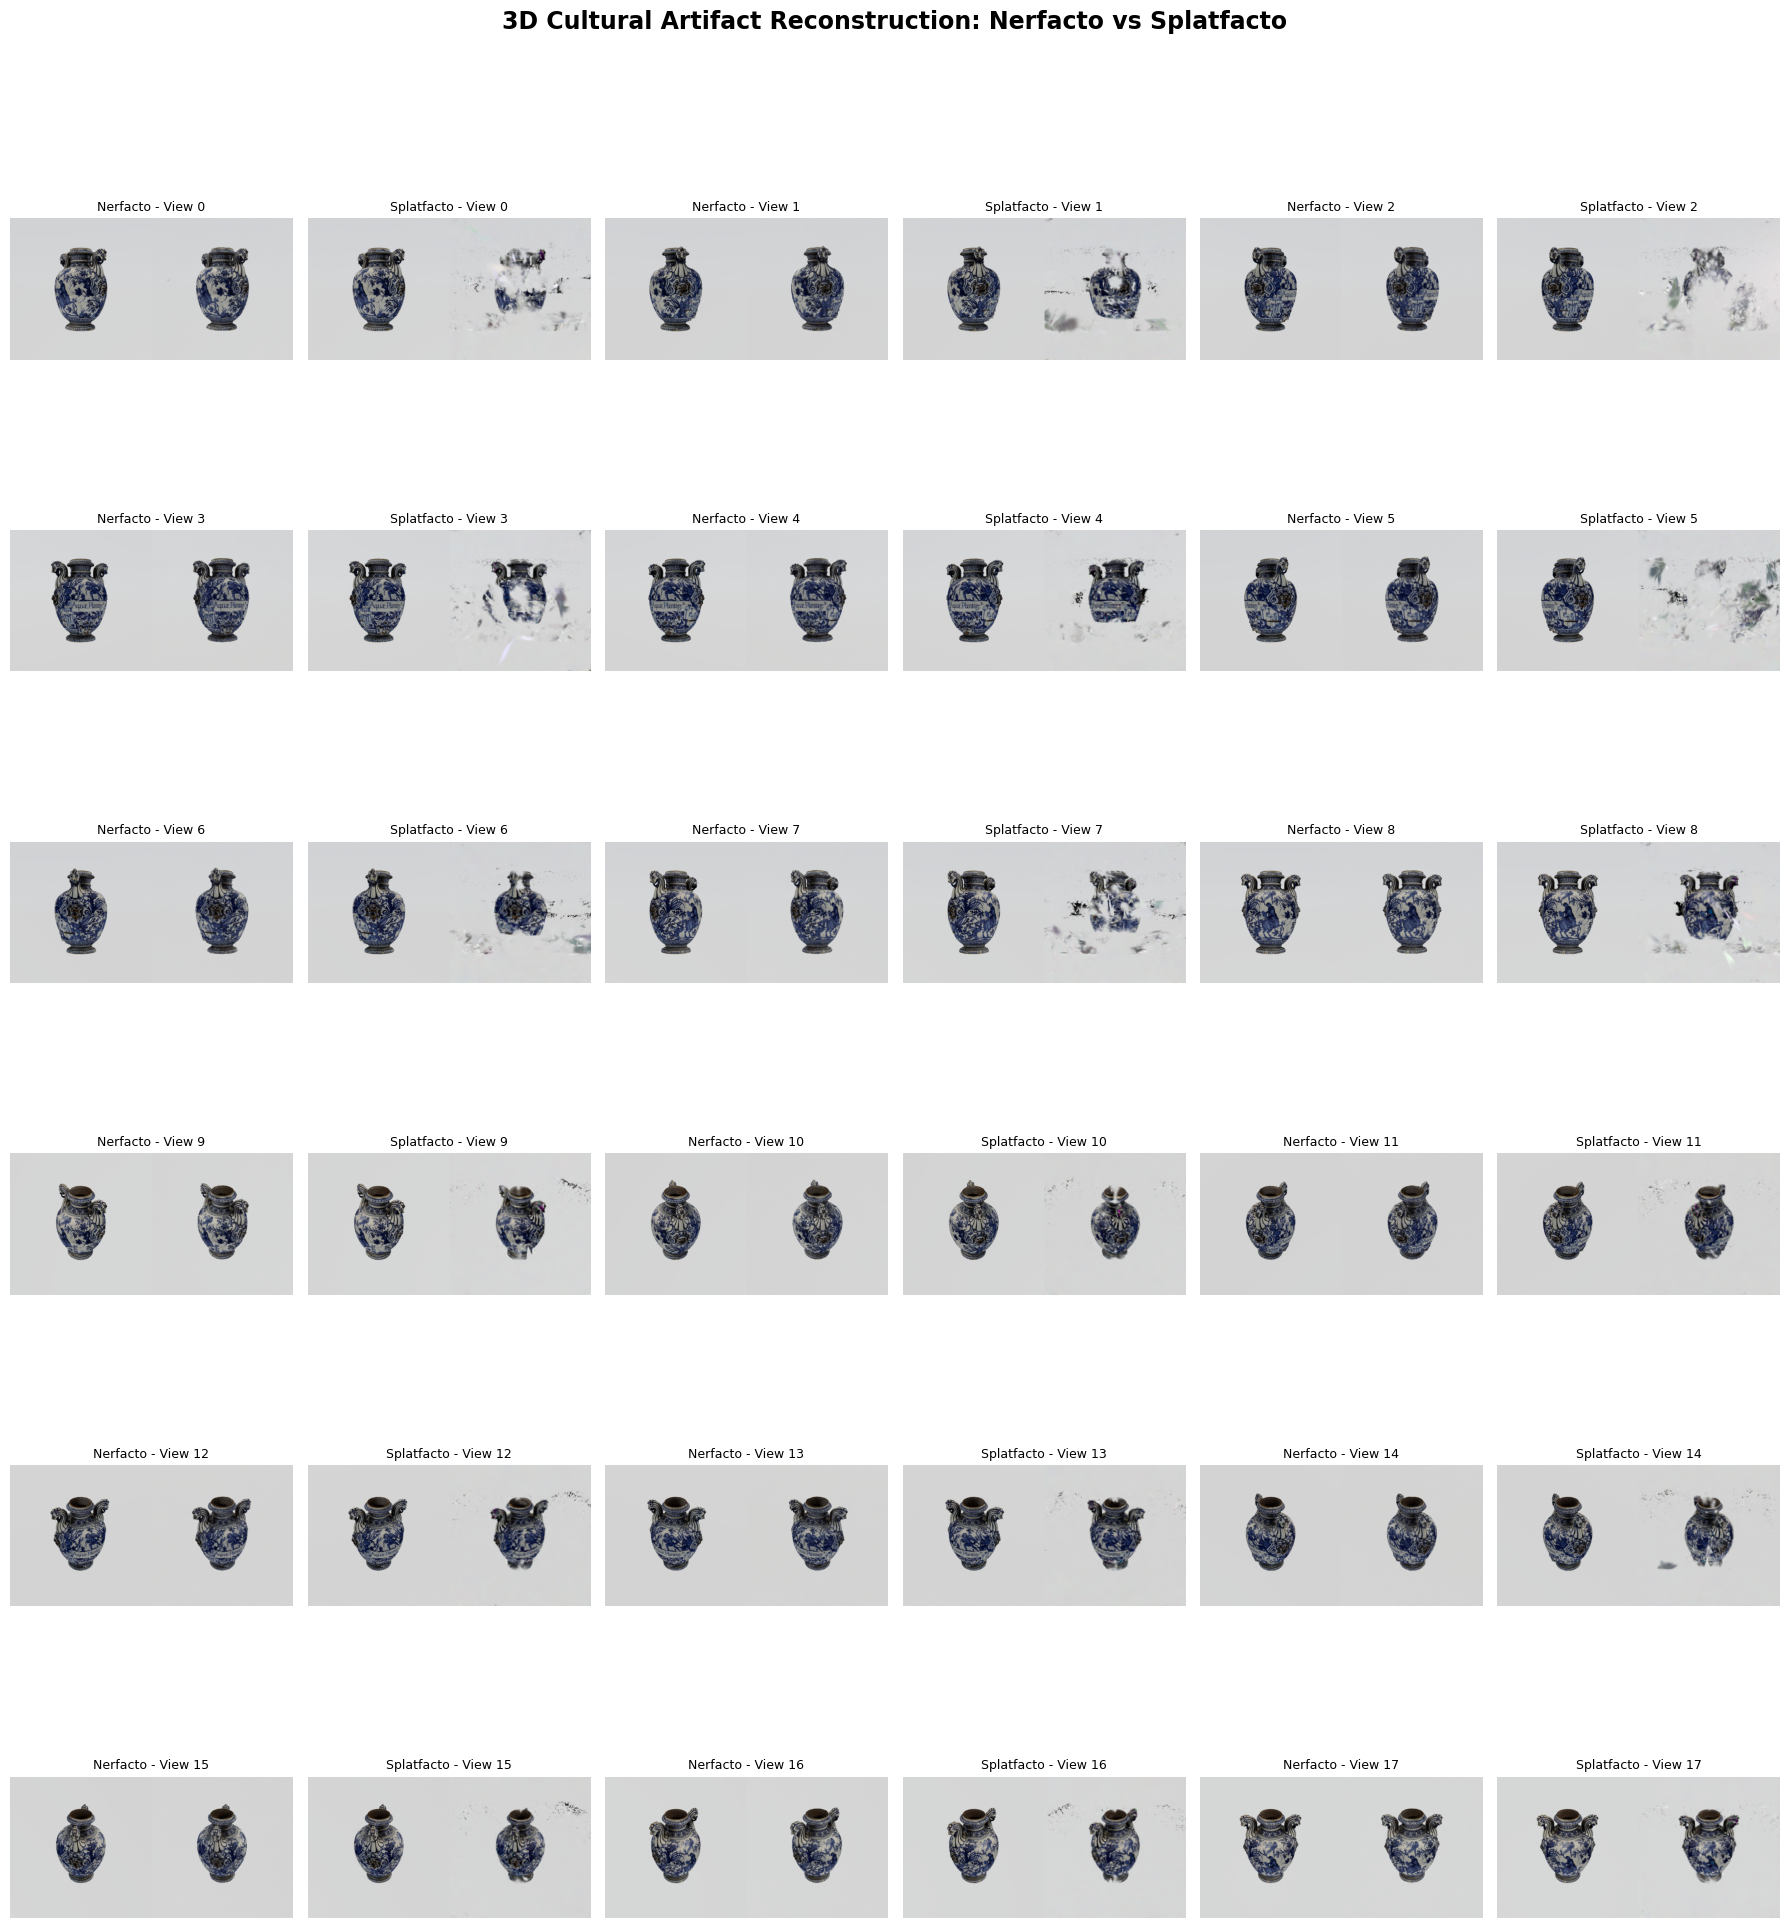


Comparison figure saved successfully!
File: /kaggle/working/Nerfacto_vs_Splatfacto_Comparison.png
Compared views: 18


In [26]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Image folders
nerfacto_dir = NERF_RUN_DIR / "eval_renders"

splatfacto_dir = Path(
    "/kaggle/working/splatfacto_eval_renders"
)

# Output file
output_file = Path(
    "/kaggle/working/Nerfacto_vs_Splatfacto_Comparison.png"
)

# Create comparison grid
fig, axes = plt.subplots(6, 6, figsize=(18, 21))

for i in range(18):
    row = i // 3
    pair_col = (i % 3) * 2

    filename = f"eval_img_{i:04d}.png"

    nerfacto_image = Image.open(
        nerfacto_dir / filename
    ).convert("RGB")

    splatfacto_image = Image.open(
        splatfacto_dir / filename
    ).convert("RGB")

    # Nerfacto image
    axes[row, pair_col].imshow(nerfacto_image)
    axes[row, pair_col].set_title(
        f"Nerfacto - View {i}",
        fontsize=9
    )
    axes[row, pair_col].axis("off")

    # Splatfacto image
    axes[row, pair_col + 1].imshow(splatfacto_image)
    axes[row, pair_col + 1].set_title(
        f"Splatfacto - View {i}",
        fontsize=9
    )
    axes[row, pair_col + 1].axis("off")

fig.suptitle(
    "3D Cultural Artifact Reconstruction: Nerfacto vs Splatfacto",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    output_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nComparison figure saved successfully!")
print("File:", output_file)
print("Compared views:", 18)

In [27]:
from pathlib import Path
from html import escape

nerfacto_dir = NERF_RUN_DIR / "eval_renders"

splatfacto_dir = Path(
    "/kaggle/working/splatfacto_eval_renders"
)

output_dir = Path("/kaggle/working/Nerfacto_Splatfacto_HTML")
output_dir.mkdir(exist_ok=True)

# Copy images into the HTML package
for i in range(18):
    filename = f"eval_img_{i:04d}.png"

    (output_dir / f"nerfacto_{filename}").write_bytes(
        (nerfacto_dir / filename).read_bytes()
    )

    (output_dir / f"splatfacto_{filename}").write_bytes(
        (splatfacto_dir / filename).read_bytes()
    )

# Build HTML content
cards = []

for i in range(18):
    filename = f"eval_img_{i:04d}.png"

    cards.append(f"""
    <section class="view">
        <h2>Evaluation View {i + 1}</h2>
        <div class="comparison">
            <div>
                <h3>Nerfacto</h3>
                <img src="nerfacto_{filename}" alt="Nerfacto view {i + 1}">
            </div>
            <div>
                <h3>Splatfacto</h3>
                <img src="splatfacto_{filename}" alt="Splatfacto view {i + 1}">
            </div>
        </div>
    </section>
    """)

html_content = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Nerfacto vs Splatfacto - Cultural Artifact Reconstruction</title>
<style>
body {
    font-family: Arial, sans-serif;
    margin: 0;
    padding: 25px;
    background: #f3f4f6;
    color: #202124;
}
header {
    text-align: center;
    padding: 25px;
    background: #202b3c;
    color: white;
    border-radius: 12px;
    margin-bottom: 25px;
}
.view {
    background: white;
    padding: 18px;
    margin: 22px auto;
    max-width: 1100px;
    border-radius: 12px;
    box-shadow: 0 2px 8px #0002;
}
.view h2 { text-align: center; }
.comparison {
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 20px;
}
.comparison div { text-align: center; }
img {
    width: 100%;
    height: auto;
    object-fit: contain;
    border: 1px solid #ddd;
    border-radius: 8px;
}
h3 { color: #344b70; }
footer {
    text-align: center;
    margin: 30px;
    color: #666;
}
@media(max-width: 650px) {
    .comparison { grid-template-columns: 1fr; }
}
</style>
</head>
<body>
<header>
<h1>Nerfacto vs Splatfacto</h1>
<h2>Digital Preservation and Interactive Visualization of Cultural Artifacts</h2>
<p>Vietnamese Ceramic Vase Reconstruction | 18 Evaluation Views</p>
</header>
""" + "\n".join(cards) + """
<footer>
<p>Experimental comparison using Nerfstudio evaluation renders.</p>
</footer>
</body>
</html>
"""

html_file = output_dir / "index.html"
html_file.write_text(html_content, encoding="utf-8")

print("HTML comparison created successfully!")
print("HTML file:", html_file)
print("Images included: 36")
print("Evaluation views: 18")

HTML comparison created successfully!
HTML file: /kaggle/working/Nerfacto_Splatfacto_HTML/index.html
Images included: 36
Evaluation views: 18


In [28]:
from pathlib import Path
from IPython.display import FileLink, display
import base64

folder = Path("/kaggle/working/Nerfacto_Splatfacto_HTML")

html = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Nerfacto vs Splatfacto</title>
<style>
body {
    font-family: Arial, sans-serif;
    background: #f2f4f8;
    color: #202b3c;
    margin: 0;
    padding: 25px;
}
header {
    background: #202b3c;
    color: white;
    padding: 25px;
    text-align: center;
    border-radius: 12px;
    margin-bottom: 25px;
}
.view {
    background: white;
    max-width: 1100px;
    margin: 20px auto;
    padding: 18px;
    border-radius: 12px;
}
.comparison {
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 18px;
}
.comparison div { text-align: center; }
img {
    width: 100%;
    height: auto;
    object-fit: contain;
    border: 1px solid #ddd;
    border-radius: 8px;
}
h3 { color: #344b70; }
@media(max-width: 650px) {
    .comparison { grid-template-columns: 1fr; }
}
</style>
</head>
<body>
<header>
<h1>Nerfacto vs Splatfacto</h1>
<h2>Digital Preservation and Interactive Visualization of Cultural Artifacts</h2>
<p>Vietnamese Ceramic Vase | 18 Matching Evaluation Views</p>
</header>
"""

for i in range(18):
    filename = f"eval_img_{i:04d}.png"

    image_html = []

    for method in ["nerfacto", "splatfacto"]:
        image_path = folder / f"{method}_{filename}"

        if not image_path.exists():
            raise FileNotFoundError(f"Missing image: {image_path}")

        encoded = base64.b64encode(
            image_path.read_bytes()
        ).decode("utf-8")

        image_html.append(f"""
        <div>
            <h3>{method.capitalize()}</h3>
            <img src="data:image/png;base64,{encoded}"
                 alt="{method} view {i + 1}">
        </div>
        """)

    html += f"""
    <section class="view">
        <h2>Evaluation View {i + 1}</h2>
        <div class="comparison">
            {''.join(image_html)}
        </div>
    </section>
    """

html += """
</body>
</html>
"""

output = Path(
    "/kaggle/working/Nerfacto_vs_Splatfacto_Standalone.html"
)

output.write_text(html, encoding="utf-8")

print("Standalone HTML created successfully!")
print("File size:", round(output.stat().st_size / (1024**2), 2), "MB")

display(FileLink(str(output)))

Standalone HTML created successfully!
File size: 14.13 MB


/kaggle/working/Nerfacto_vs_Splatfacto_Standalone.html

## 17. Model sizes and PLY export for the interactive viewer

Records the checkpoint size of both models (a project-plan metric), then exports the Splatfacto Gaussian model and the Nerfacto point cloud to PLY files for the web viewers.


In [29]:
from pathlib import Path

nerfacto_checkpoint = Path(
    "/kaggle/input/datasets/shahdhyani/nerfacto-backup-zip/"
    "nerfacto/2026-11-08_193704/"
    "nerfstudio_models/step-000004999.ckpt"
)

splatfacto_checkpoint = RUN_DIR / "nerfstudio_models" / "step-000004999.ckpt"

for name, path in [
    ("Nerfacto", nerfacto_checkpoint),
    ("Splatfacto", splatfacto_checkpoint)
]:
    print(f"\n{name}")
    print("Checkpoint exists:", path.exists())

    if path.exists():
        print(
            "Model checkpoint size:",
            round(path.stat().st_size / (1024**2), 2),
            "MB"
        )


Nerfacto
Checkpoint exists: False

Splatfacto
Checkpoint exists: True
Model checkpoint size: 300.22 MB


In [30]:
import os

splat_config = "/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto"

# Find the actual timestamped run folder
runs = [
    os.path.join(splat_config, name)
    for name in os.listdir(splat_config)
    if os.path.isfile(os.path.join(splat_config, name, "config.yml"))
]

print("Available Splatfacto runs:")
for path in runs:
    print(path)

Available Splatfacto runs:
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746


In [31]:
import sys
import numpy as np
import torch

# Allow the NumPy scalar type requested by the checkpoint-loading error
try:
    numpy_scalar = np._core.multiarray.scalar
except AttributeError:
    numpy_scalar = np.core.multiarray.scalar

torch.serialization.add_safe_globals([numpy_scalar])

# Export arguments
sys.argv = [
    "ns-export",
    "gaussian-splat",
    "--load-config",
    str(CONFIG_PATH),
    "--output-dir",
    "/kaggle/working/3D_Viewer_Exports",
    "--output-filename",
    "ceramic_splatfacto.ply",
    "--ply-color-mode",
    "rgb"
]

# Run Nerfstudio exporter in this same Python process
from nerfstudio.scripts.exporter import entrypoint
entrypoint()

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Warning: load_3D_points set to true but no point cloud found. splatfacto will use random point cloud initialization.

Loading latest checkpoint from load_dir

✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfstudio_models/step-00000499
9.ckpt

Warning: model has higher level of spherical harmonics, ignoring them and only export rgb.

In [32]:
import os

output_dir = "/kaggle/working/3D_Viewer_Exports"
ply_path = os.path.join(output_dir, "ceramic_splatfacto.ply")

print("PLY file exists:", os.path.isfile(ply_path))

if os.path.isfile(ply_path):
    size_mb = os.path.getsize(ply_path) / (1024 * 1024)
    print("PLY file size:", round(size_mb, 2), "MB")
    print("Export successful!")
else:
    print("PLY file not found. Check the export cell for additional output.")
    print("Files in output directory:", os.listdir(output_dir) if os.path.isdir(output_dir) else "Directory not found")

PLY file exists: True
PLY file size: 24.23 MB
Export successful!


In [36]:
import os
import zipfile
from pathlib import Path

INPUT = Path("/kaggle/input")
EXTRACT_DIR = Path("/kaggle/working/nerfacto_backup_extracted")

def find_nerf_run_dir() -> Path:
    """Locate the extracted Nerfacto backup; extract the zip if needed."""
    for cfg in INPUT.rglob("config.yml"):            # dataset already extracted
        if "nerfacto" in str(cfg):
            return cfg.parent
    for z in INPUT.rglob("*.zip"):                   # still packaged -> extract once
        if "erfacto" in z.name:
            if not EXTRACT_DIR.exists():
                print("Extracting:", z)
                with zipfile.ZipFile(z) as f:
                    f.extractall(EXTRACT_DIR)
            for cfg in EXTRACT_DIR.rglob("config.yml"):
                if "nerfacto" in str(cfg):
                    return cfg.parent
    raise FileNotFoundError(
        "Nerfacto backup not found under /kaggle/input.\n"
        "Fix: Add Input -> attach 'nerfacto-backup-zip' (or the Part 1 notebook "
        "output), then re-run this cell."
    )

ACTUAL_RUN = find_nerf_run_dir()
print("Resolved Nerfacto run dir:", ACTUAL_RUN)

EXPECTED_RUN = Path(
    "/kaggle/working/nerfstudio_outputs/"
    "ceramic_vases_1/nerfacto/2026-11-08_193704"
)
EXPECTED_RUN.parent.mkdir(parents=True, exist_ok=True)

# Remove a stale/broken link left by the previous version of this cell.
if EXPECTED_RUN.is_symlink():
    EXPECTED_RUN.unlink()

if not EXPECTED_RUN.exists():
    os.symlink(ACTUAL_RUN, EXPECTED_RUN)
    print("Checkpoint link created successfully!")
else:
    print("Expected location already exists.")

# Real verification: every artifact the comparison/export cells need.
ckpt = EXPECTED_RUN / "nerfstudio_models" / "step-000004999.ckpt"
print("config.yml            :", (EXPECTED_RUN / "config.yml").is_file())
print("Checkpoint accessible :", ckpt.is_file())
if ckpt.is_file():
    print("Checkpoint size (MB)  :", round(ckpt.stat().st_size / (1024**2), 2))
print("Eval renders (png)    :", len(list((EXPECTED_RUN / "eval_renders").glob("*.png"))))

Resolved Nerfacto run dir: /kaggle/input/datasets/dhyani1611/nerfacto-backup-zip
Checkpoint link created successfully!
config.yml            : True
Checkpoint accessible : True
Checkpoint size (MB)  : 231.68
Eval renders (png)    : 90


In [35]:
from pathlib import Path
print("Attached inputs:", [p.name for p in Path("/kaggle/input").iterdir()])

Attached inputs: ['datasets']


In [43]:
import sys
import numpy as np
import torch

# Stable torch.load patch — cannot recurse, safe to re-run any number of times
def trusted_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return torch.serialization.load(*args, **kwargs)

torch.load = trusted_torch_load

try:
    numpy_scalar = np._core.multiarray.scalar
except AttributeError:
    numpy_scalar = np.core.multiarray.scalar
torch.serialization.add_safe_globals([numpy_scalar])

NERF_CONFIG = (
    "/kaggle/working/nerfstudio_outputs/"
    "ceramic_vases_1/nerfacto/2026-11-08_193704/config.yml"
)

sys.argv = [
    "ns-export",
    "pointcloud",
    "--load-config", NERF_CONFIG,
    "--output-dir", "/kaggle/working/3D_Viewer_Exports",
    "--num-points", "500000",
    "--remove-outliers", "True",
    "--save-world-frame", "True",
]

from nerfstudio.scripts.exporter import entrypoint
entrypoint()

[08:27:17] Auto image downscale factor of 1                                                 ]8;id=968027;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=715342;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

Started threads


Setting up evaluation dataset...

Caching all 18 images.

Output()

WARNING: Using a slow implementation for the SHEncoding module. 

... (26 outputs left out)

──────────────────────────────────────────────────────── Error ─────────────────────────────────────────────────────────

No checkpoint directory found at                                            
            /kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfstudio_models,

Please make sure the checkpoint exists, they should be generated periodically during training

SystemExit: 1

In [44]:
import os

folder = "/kaggle/working/3D_Viewer_Exports"

print("Export folder exists:", os.path.exists(folder))

for filename in os.listdir(folder):
    path = os.path.join(folder, filename)
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{filename} — {size_mb:.2f} MB")

Export folder exists: True
ceramic_splatfacto.ply — 24.23 MB


## 18. Interactive 3D viewer HTML files

Builds two self-contained viewer pages — a point-cloud viewer for the Nerfacto export and a Gaussian-splat viewer for the Splatfacto export — and packages them with the PLY models into `Ceramic_Interactive_3D_Viewer.zip` (project-plan Step 7).


In [47]:
from pathlib import Path

html = r'''<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<title>Nerfacto Ceramic 3D Viewer</title>
<style>
body { margin:0; background:#101827; color:white; font-family:Arial; }
header { padding:15px 22px; background:#17243a; }
#controls { padding:12px 22px; }
button { padding:9px 14px; margin-right:6px; cursor:pointer; }
#viewer { width:100%; height:75vh; min-height:450px; }
#status { padding:10px 22px; color:#9bd5ff; }
</style>
<script type="importmap">
{
 "imports":{
  "three":"https://cdn.jsdelivr.net/npm/three@0.180.0/build/three.module.js",
  "three/addons/":"https://cdn.jsdelivr.net/npm/three@0.180.0/examples/jsm/"
 }
}
</script>
</head>
<body>
<header>
<h2>Nerfacto — Vietnamese Ceramic Artifact</h2>
<p>Interactive 3D point-cloud reconstruction</p>
</header>

<div id="controls">
<input type="file" id="file" accept=".ply">
<button id="reset">Reset View</button>
<button id="front">Front</button>
<button id="top">Top</button>
<button id="side">Side</button>
</div>

<div id="viewer"></div>
<div id="status">Select point_cloud.ply</div>

<script type="module">
import * as THREE from "three";
import {PLYLoader} from "three/addons/loaders/PLYLoader.js";
import {OrbitControls} from "three/addons/controls/OrbitControls.js";

const box = document.getElementById("viewer");
const status = document.getElementById("status");

const scene = new THREE.Scene();
scene.background = new THREE.Color(0x101827);

const camera = new THREE.PerspectiveCamera(
  45, box.clientWidth/box.clientHeight, 0.001, 10000
);

const renderer = new THREE.WebGLRenderer({antialias:true});
renderer.setPixelRatio(Math.min(window.devicePixelRatio,2));
renderer.setSize(box.clientWidth,box.clientHeight);
box.appendChild(renderer.domElement);

const controls = new OrbitControls(camera,renderer.domElement);
controls.enableDamping = true;
controls.target.set(0,0,0);

let model=null;
let radius=1;

function setCamera(x,y,z){
 camera.position.set(x,y,z).add(controls.target);
 controls.update();
}

function animate(){
 requestAnimationFrame(animate);
 controls.update();
 renderer.render(scene,camera);
}
animate();

document.getElementById("file").addEventListener("change",async e=>{
 const file=e.target.files[0];
 if(!file)return;

 status.textContent="Loading point cloud...";

 try{
  const data=await file.arrayBuffer();
  const geometry=new PLYLoader().parse(data);

  geometry.computeBoundingBox();
  const center=geometry.boundingBox.getCenter(new THREE.Vector3());
  const size=geometry.boundingBox.getSize(new THREE.Vector3());

  geometry.translate(-center.x,-center.y,-center.z);

  radius=Math.max(size.x,size.y,size.z)*0.5;
  if(!Number.isFinite(radius)||radius<=0)radius=1;

  if(model){
   scene.remove(model);
   model.geometry.dispose();
   model.material.dispose();
  }

  const material=new THREE.PointsMaterial({
   size:radius*0.006,
   sizeAttenuation:false,
   vertexColors:!!geometry.attributes.color
  });

  model=new THREE.Points(geometry,material);
  scene.add(model);

  camera.near=0.001;
  camera.far=radius*100;
  camera.updateProjectionMatrix();

  controls.target.set(0,0,0);
  setCamera(0,0,radius*3);

  status.textContent=
   "Loaded successfully: "+
   geometry.attributes.position.count.toLocaleString()+
   " points. Drag to rotate and scroll to zoom.";

 }catch(err){
  console.error(err);
  status.textContent="Error: "+err.message;
 }
});

document.getElementById("reset").onclick=()=>{
 setCamera(0,0,radius*3);
};
document.getElementById("front").onclick=()=>{
 setCamera(0,0,radius*3);
};
document.getElementById("top").onclick=()=>{
 setCamera(0,radius*3,0);
};
document.getElementById("side").onclick=()=>{
 setCamera(radius*3,0,0);
};

window.addEventListener("resize",()=>{
 camera.aspect=box.clientWidth/box.clientHeight;
 camera.updateProjectionMatrix();
 renderer.setSize(box.clientWidth,box.clientHeight);
});
</script>
</body>
</html>'''

path=Path("/kaggle/working/Ceramic_3D_Viewer/Nerfacto_PointCloud_Viewer.html")
path.parent.mkdir(parents=True, exist_ok=True)   # creates the missing folder
path.write_text(html,encoding="utf-8")
print("Updated viewer:",path)

Updated viewer: /kaggle/working/Ceramic_3D_Viewer/Nerfacto_PointCloud_Viewer.html


In [48]:
from pathlib import Path

html = r'''<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Ceramic Artifact - Splatfacto 3D Viewer</title>

<style>
body {
    margin: 0;
    background: #101827;
    color: white;
    font-family: Arial, sans-serif;
}
header { padding: 18px 24px; background: #17243a; }
h2 { margin: 0 0 8px; }
p { color: #bdc9d9; }
#toolbar { padding: 14px 24px; }
#viewer { width: 100%; height: 72vh; min-height: 450px; }
#viewer canvas { width: 100%; height: 100%; display: block; }
#status { padding: 12px 24px; color: #9bd5ff; }
button { padding: 9px 15px; cursor: pointer; }
</style>

<script type="importmap">
{
  "imports": {
    "three": "https://cdn.jsdelivr.net/npm/three@0.180.0/build/three.module.js",
    "three/addons/": "https://cdn.jsdelivr.net/npm/three@0.180.0/examples/jsm/",
    "@sparkjsdev/spark": "https://sparkjs.dev/releases/spark/2.4.0/spark.module.js"
  }
}
</script>
</head>

<body>
<header>
<h2>Vietnamese Ceramic Artifact — Splatfacto</h2>
<p>Interactive 3D Gaussian Splat Reconstruction</p>
</header>

<div id="toolbar">
<label>Select Splatfacto PLY:
<input type="file" id="file" accept=".ply">
</label>
<button id="reset">Reset Camera</button>
</div>

<div id="viewer"></div>
<div id="status">Select ceramic_splatfacto.ply to load the model.</div>

<script type="module">
import * as THREE from "three";
import { OrbitControls } from "three/addons/controls/OrbitControls.js";
import { SparkRenderer, SplatMesh } from "@sparkjsdev/spark";

const container = document.getElementById("viewer");
const status = document.getElementById("status");

const scene = new THREE.Scene();
scene.background = new THREE.Color(0x101827);

const camera = new THREE.PerspectiveCamera(
    60, container.clientWidth / container.clientHeight, 0.01, 10000
);

const renderer = new THREE.WebGLRenderer({ antialias: false });
renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
renderer.setSize(container.clientWidth, container.clientHeight);
container.appendChild(renderer.domElement);

const spark = new SparkRenderer({ renderer });
scene.add(spark);

const controls = new OrbitControls(camera, renderer.domElement);
controls.enableDamping = true;
controls.dampingFactor = 0.06;

let splatMesh = null;
let defaultPosition = new THREE.Vector3();

renderer.setAnimationLoop(() => {
    controls.update();
    renderer.render(scene, camera);
});

document.getElementById("file").addEventListener("change", async (event) => {
    const file = event.target.files[0];
    if (!file) return;

    status.textContent = "Reading Gaussian PLY file...";

    try {
        const fileBytes = new Uint8Array(await file.arrayBuffer());

        if (splatMesh) {
            scene.remove(splatMesh);
            splatMesh.dispose();
            splatMesh = null;
        }

        splatMesh = new SplatMesh({
            fileBytes,
            fileName: file.name
        });

        scene.add(splatMesh);

        status.textContent = "Decoding and preparing Gaussian splats...";

        await splatMesh.initialized;

        const bounds = splatMesh.getBoundingBox();
        const center = bounds.getCenter(new THREE.Vector3());
        const size = bounds.getSize(new THREE.Vector3());
        const radius = Math.max(size.length() / 2, 0.1);

        splatMesh.position.sub(center);

        defaultPosition.set(0, 0, radius * 2.8);
        camera.position.copy(defaultPosition);
        camera.near = Math.max(radius / 1000, 0.001);
        camera.far = radius * 100;
        camera.updateProjectionMatrix();

        controls.target.set(0, 0, 0);
        controls.update();

        status.textContent =
            "Successfully loaded " +
            splatMesh.numSplats.toLocaleString() +
            " Gaussian splats. Drag to rotate; scroll to zoom; right-drag to pan.";

    } catch (error) {
        console.error(error);
        status.textContent = "Error loading model: " + error.message;
    }
});

document.getElementById("reset").addEventListener("click", () => {
    camera.position.copy(defaultPosition);
    controls.target.set(0, 0, 0);
    controls.update();
});

window.addEventListener("resize", () => {
    camera.aspect = container.clientWidth / container.clientHeight;
    camera.updateProjectionMatrix();
    renderer.setSize(container.clientWidth, container.clientHeight);
});
</script>
</body>
</html>'''

output = Path(
    "/kaggle/working/Ceramic_3D_Viewer/Splatfacto_Gaussian_Viewer.html"
)

output.write_text(html, encoding="utf-8")

print("Updated Splatfacto viewer:", output)
print("File size:", round(output.stat().st_size / 1024, 2), "KB")

Updated Splatfacto viewer: /kaggle/working/Ceramic_3D_Viewer/Splatfacto_Gaussian_Viewer.html
File size: 4.31 KB


In [50]:
import os
for d in ["/kaggle/working/3D_Viewer_Exports", "/kaggle/working/Ceramic_3D_Viewer"]:
    print("==", d)
    print(sorted(os.listdir(d)) if os.path.isdir(d) else "MISSING")

== /kaggle/working/3D_Viewer_Exports
['ceramic_splatfacto.ply']
== /kaggle/working/Ceramic_3D_Viewer
['Nerfacto_PointCloud_Viewer.html', 'Splatfacto_Gaussian_Viewer.html']


In [51]:
# 1a) link the run-timestamp names the config references
import os, re
from pathlib import Path

ACTUAL_RUN = Path("/kaggle/input/datasets/dhyani1611/nerfacto-backup-zip")
text = (ACTUAL_RUN / "config.yml").read_text()
stamps = sorted(set(re.findall(r"\d{4}-\d{2}-\d{2}_\d{6}", text)))
print("Referenced timestamps:", stamps)

base = Path("/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto")
base.mkdir(parents=True, exist_ok=True)
for ts in stamps:
    link = base / ts
    if link.is_symlink():
        link.unlink()
    if not link.exists():
        os.symlink(ACTUAL_RUN, link)
        print("Linked:", link.name)
    else:
        print("Exists:", link.name)

Referenced timestamps: ['2026-11-14_055958']
Linked: 2026-11-14_055958


In [52]:
import os, sys
import numpy as np
import torch

def trusted_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return torch.serialization.load(*args, **kwargs)
torch.load = trusted_torch_load

# resolve the real run folder instead of the literal {timestamp}
splat_root = "/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto"
runs = [os.path.join(splat_root, n) for n in os.listdir(splat_root)
        if os.path.isfile(os.path.join(splat_root, n, "config.yml"))]
assert runs, "No Splatfacto run folder found - has training finished in this session?"
run_dir = max(runs, key=os.path.getmtime)
print("Using Splatfacto run:", run_dir)

sys.argv = [
    "ns-export", "gaussian-splat",
    "--load-config", os.path.join(run_dir, "config.yml"),
    "--output-dir", "/kaggle/working/3D_Viewer_Exports",
    "--output-filename", "ceramic_splatfacto.ply",
    "--ply-color-mode", "rgb",
]
from nerfstudio.scripts.exporter import entrypoint
entrypoint()

Using Splatfacto run: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746


Warning: load_3D_points set to true but no point cloud found. splatfacto will use random point cloud initialization.

Loading latest checkpoint from load_dir

✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746/nerfstudio_models/step-00000499
9.ckpt

Warning: model has higher level of spherical harmonics, ignoring them and only export rgb.

In [61]:
import os, shutil, zipfile

folder = "/kaggle/working/Ceramic_3D_Viewer"
source = "/kaggle/working/3D_Viewer_Exports"
os.makedirs(folder, exist_ok=True)

required = [
    "point_cloud.ply",
    "ceramic_splatfacto.ply",
    "Nerfacto_PointCloud_Viewer.html",
    "Splatfacto_Gaussian_Viewer.html",
]

for filename in required[:2]:
    src, dst = os.path.join(source, filename), os.path.join(folder, filename)
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

missing = [f for f in required if not os.path.exists(os.path.join(folder, f))]
for filename in required:
    print(f"{filename:38s}", "OK" if os.path.exists(os.path.join(folder, filename)) else "MISSING")

if missing:
    print("\nZIP not built yet — missing:", missing)
else:
    zip_path = "/kaggle/working/Ceramic_Interactive_3D_Viewer.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for filename in required:
            z.write(os.path.join(folder, filename), arcname=filename)
    print("\nComplete viewer ZIP created!")
    print("Path:", zip_path)
    print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

point_cloud.ply                        OK
ceramic_splatfacto.ply                 OK
Nerfacto_PointCloud_Viewer.html        OK
Splatfacto_Gaussian_Viewer.html        OK

Complete viewer ZIP created!
Path: /kaggle/working/Ceramic_Interactive_3D_Viewer.zip
Size: 30.4 MB


In [57]:
import os
from pathlib import Path

nerf_backup = Path("/kaggle/input/datasets/dhyani1611/nerfacto-backup-zip")
splat_root  = Path("/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto")
data_dir    = Path("/kaggle/working/ceramic_vases_1")

splat_runs = [d for d in splat_root.iterdir() if (d / "config.yml").is_file()] if splat_root.is_dir() else []
print("Nerfacto backup config.yml :", (nerf_backup / "config.yml").is_file())
print("Nerfacto checkpoint        :", (nerf_backup / "nerfstudio_models/step-000004999.ckpt").is_file())
print("Splatfacto run folder      :", splat_runs[-1] if splat_runs else "MISSING")
print("transforms.json (data)     :", (data_dir / "transforms.json").is_file())

Nerfacto backup config.yml : True
Nerfacto checkpoint        : True
Splatfacto run folder      : /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746
transforms.json (data)     : True


In [58]:
import os, re, sys
import numpy as np
import torch
from pathlib import Path

def trusted_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return torch.serialization.load(*args, **kwargs)
torch.load = trusted_torch_load

try:
    np_scalar = np._core.multiarray.scalar
except AttributeError:
    np_scalar = np.core.multiarray.scalar
torch.serialization.add_safe_globals([np_scalar])

ACTUAL_RUN = Path("/kaggle/input/datasets/dhyani1611/nerfacto-backup-zip")
base = Path("/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto")
base.mkdir(parents=True, exist_ok=True)
for ts in sorted(set(re.findall(r"\d{4}-\d{2}-\d{2}_\d{6}", (ACTUAL_RUN / "config.yml").read_text()))):
    link = base / ts
    if link.is_symlink():
        link.unlink()
    if not link.exists():
        os.symlink(ACTUAL_RUN, link)
NERF_RUN_DIR = base / "2026-11-08_193704"

out = Path("/kaggle/working/3D_Viewer_Exports/point_cloud.ply")
if out.is_file():
    print("point_cloud.ply already exists - skipping export.")
else:
    sys.argv = [
        "ns-export", "pointcloud",
        "--load-config", str(NERF_RUN_DIR / "config.yml"),
        "--output-dir", "/kaggle/working/3D_Viewer_Exports",
        "--num-points", "500000",
        "--remove-outliers", "True",
        "--normal-method", "open3d",
        "--save-world-frame", "True",
    ]
    from nerfstudio.scripts.exporter import entrypoint
    entrypoint()

print("point_cloud.ply :", out.is_file(),
      "| MB:", round(out.stat().st_size / (1024**2), 2) if out.is_file() else "-")

[08:54:12] Auto image downscale factor of 1                                                 ]8;id=82909;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=831244;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

Started threads


Setting up evaluation dataset...

Caching all 18 images.

Output()

WARNING: Using a slow implementation for the SHEncoding module. 

... (33 outputs left out)

✅ Generated PointCloud with 501760 points.

Saving Point Cloud...

✅ Saving Point Cloud

point_cloud.ply : True | MB: 12.92


In [59]:
import os, sys
import numpy as np
import torch
from pathlib import Path

def trusted_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return torch.serialization.load(*args, **kwargs)
torch.load = trusted_torch_load

splat_root = Path("/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto")
run_dir = sorted([d for d in splat_root.iterdir() if (d / "config.yml").is_file()],
                 key=os.path.getmtime)[-1]
out = Path("/kaggle/working/3D_Viewer_Exports/ceramic_splatfacto.ply")
print("Using Splatfacto run:", run_dir)

if out.is_file():
    print("ceramic_splatfacto.ply already exists - skipping export.")
else:
    sys.argv = [
        "ns-export", "gaussian-splat",
        "--load-config", str(run_dir / "config.yml"),
        "--output-dir", "/kaggle/working/3D_Viewer_Exports",
        "--output-filename", "ceramic_splatfacto.ply",
        "--ply-color-mode", "rgb",
    ]
    from nerfstudio.scripts.exporter import entrypoint
    entrypoint()

print("ceramic_splatfacto.ply :", out.is_file(),
      "| MB:", round(out.stat().st_size / (1024**2), 2) if out.is_file() else "-")

Using Splatfacto run: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_fresh/splatfacto/2026-11-14_075746
ceramic_splatfacto.ply already exists - skipping export.
ceramic_splatfacto.ply : True | MB: 24.23


In [60]:
from pathlib import Path

TEMPLATE = r'''<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<title>__TITLE__</title>
<style>
 body { margin:0; background:#101827; color:white; font-family:Arial; }
 header { padding:15px 22px; background:#17243a; }
 #controls { padding:12px 22px; }
 button { padding:9px 14px; margin-right:6px; cursor:pointer; }
 #viewer { width:100%; height:75vh; min-height:450px; }
 #status { padding:10px 22px; color:#9bd5ff; }
 label { margin-left:14px; }
</style>
<script type="importmap">
{ "imports": {
  "three":"https://cdn.jsdelivr.net/npm/three@0.180.0/build/three.module.js",
  "three/addons/":"https://cdn.jsdelivr.net/npm/three@0.180.0/examples/jsm/"
 } }
</script>
</head>
<body>
<header><h2>__TITLE__</h2><p>__SUBTITLE__</p></header>
<div id="controls">
 <input type="file" id="file" accept=".ply">
 <button id="reset">Reset View</button>
 <button id="front">Front</button>
 <button id="top">Top</button>
 <button id="side">Side</button>
 <label>Point size <input type="range" id="psize" min="0.2" max="4" step="0.05" value="1" style="vertical-align:middle"></label>
</div>
<div id="viewer"></div>
<div id="status">__PICK__</div>
<script type="module">
import * as THREE from "three";
import {PLYLoader} from "three/addons/loaders/PLYLoader.js";
import {OrbitControls} from "three/addons/controls/OrbitControls.js";

const box = document.getElementById("viewer");
const status = document.getElementById("status");
const scene = new THREE.Scene();
scene.background = new THREE.Color(0x101827);
const camera = new THREE.PerspectiveCamera(45, box.clientWidth/box.clientHeight, 0.001, 10000);
const renderer = new THREE.WebGLRenderer({antialias:true});
renderer.setPixelRatio(Math.min(window.devicePixelRatio,2));
renderer.setSize(box.clientWidth, box.clientHeight);
box.appendChild(renderer.domElement);
const controls = new OrbitControls(camera, renderer.domElement);
controls.enableDamping = true;

let model=null, radius=1, baseSize=0.01;
const material = new THREE.PointsMaterial({size:baseSize, sizeAttenuation:true, vertexColors:true});

function setCamera(x,y,z){ camera.position.set(x,y,z).add(controls.target); controls.update(); }
function fit(){ controls.target.set(0,0,0); setCamera(0,0,radius*3); }
function animate(){ requestAnimationFrame(animate); controls.update(); renderer.render(scene,camera); }
animate();

document.getElementById("psize").addEventListener("input", e=>{
  material.size = baseSize * parseFloat(e.target.value);
});

document.getElementById("file").addEventListener("change", async e=>{
  const file = e.target.files[0]; if(!file) return;
  status.textContent = "Loading point cloud...";
  try{
    const data = await file.arrayBuffer();
    const geometry = new PLYLoader().parse(data);
    geometry.computeBoundingBox();
    const center = geometry.boundingBox.getCenter(new THREE.Vector3());
    const size = geometry.boundingBox.getSize(new THREE.Vector3());
    geometry.translate(-center.x, -center.y, -center.z);

    radius = Math.max(size.x, size.y, size.z) * 0.5;
    if(!Number.isFinite(radius) || radius <= 0) radius = 1;
    baseSize = radius * 0.008;                 // world units -> true 3D perspective
    material.size = baseSize * parseFloat(document.getElementById("psize").value);
    material.vertexColors = !!geometry.attributes.color;

    if(model){ scene.remove(model); model.geometry.dispose(); }
    model = new THREE.Points(geometry, material);
    scene.add(model);

    camera.near = radius/100;
    camera.far  = radius*50;
    camera.updateProjectionMatrix();
    fit();
    status.textContent = "Loaded " + geometry.attributes.position.count.toLocaleString() +
      " points. Drag to rotate, scroll to zoom, slider to change point size.";
  }catch(err){
    console.error(err);
    status.textContent = "Error: " + err.message;
  }
});

document.getElementById("reset").onclick = fit;
document.getElementById("front").onclick = () => setCamera(0,0, radius*3);
document.getElementById("top").onclick   = () => setCamera(0, radius*3, 0);
document.getElementById("side").onclick  = () => setCamera(radius*3, 0, 0);
window.addEventListener("resize", ()=>{
  camera.aspect = box.clientWidth/box.clientHeight;
  camera.updateProjectionMatrix();
  renderer.setSize(box.clientWidth, box.clientHeight);
});
</script>
</body>
</html>'''

viewer_dir = Path("/kaggle/working/Ceramic_3D_Viewer")
viewer_dir.mkdir(parents=True, exist_ok=True)

f1 = viewer_dir / "Nerfacto_PointCloud_Viewer.html"
f1.write_text(
    TEMPLATE.replace("__TITLE__", "Nerfacto — Vietnamese Ceramic Artifact")
            .replace("__SUBTITLE__", "Interactive 3D point-cloud reconstruction")
            .replace("__PICK__", "Select point_cloud.ply"),
    encoding="utf-8")

f2 = viewer_dir / "Splatfacto_Gaussian_Viewer.html"
f2.write_text(
    TEMPLATE.replace("__TITLE__", "Splatfacto — Vietnamese Ceramic Artifact")
            .replace("__SUBTITLE__", "Interactive 3D gaussian centers preview")
            .replace("__PICK__", "Select ceramic_splatfacto.ply"),
    encoding="utf-8")

print("Wrote:", f1)
print("Wrote:", f2)

Wrote: /kaggle/working/Ceramic_3D_Viewer/Nerfacto_PointCloud_Viewer.html
Wrote: /kaggle/working/Ceramic_3D_Viewer/Splatfacto_Gaussian_Viewer.html


In [62]:
import numpy as np
from pathlib import Path

SRC = Path("/kaggle/working/3D_Viewer_Exports/ceramic_splatfacto.ply")
DST = Path("/kaggle/working/3D_Viewer_Exports/ceramic_splatfacto_preview.ply")
OPACITY_THRESHOLD = 0.5    # raise to 0.6-0.7 if the result is still fuzzy
DROP_LARGEST_PCT  = 2.0    # drop the biggest filler gaussians

raw = SRC.read_bytes()
i = raw.index(b"end_header")
header_end = raw.index(b"\n", i) + 1
lines = raw[:header_end].decode("ascii").splitlines()
assert lines[0].strip() == "ply" and "binary_little_endian" in lines[1], "expected binary PLY"

props, dtypes, counts, elem = [], [], [], None
for line in lines[2:]:
    p = line.split()
    if not p: continue
    if p[0] == "element":
        elem, counts = p[1], counts + [(p[1], int(p[2]))]
    elif p[0] == "property" and elem == "vertex":
        tmap = {"float":"f4","double":"f8","uchar":"u1","char":"i1",
                "ushort":"u2","short":"i2","uint":"u4","int":"i4"}
        props.append(p[2]); dtypes.append(tmap[p[1]])

assert counts and counts[0][0] == "vertex", "vertex must be the first element"
n = dict(counts)["vertex"]
dtype = np.dtype(list(zip(props, dtypes)))
verts = np.frombuffer(raw[header_end:header_end + dtype.itemsize * n], dtype=dtype)
print("vertices:", n, "| first props:", props[:8])

names = set(props)
keep = np.ones(n, dtype=bool)

if "opacity" in names:
    op_raw = verts["opacity"].astype(np.float64)
    logits = op_raw.max() > 1.5
    op = 1/(1 + np.exp(-op_raw)) if logits else op_raw
    print("opacity layout:", "logits (sigmoid applied)" if logits else "already 0-1",
          "| max:", round(float(op.max()), 3))
    keep &= op > OPACITY_THRESHOLD
    print(f"opacity > {OPACITY_THRESHOLD}: kept {int(keep.sum())}/{n}")
else:
    print("no opacity property - skipping that filter")

scale_names = [p for p in props if p.startswith("scale_")]
if len(scale_names) >= 3:
    mean_scale = np.mean(np.stack([verts[p] for p in scale_names[:3]], axis=1), axis=1)
    keep &= mean_scale <= np.percentile(mean_scale, 100 - DROP_LARGEST_PCT)
    print(f"dropped top {DROP_LARGEST_PCT}% largest gaussians")

if {"red","green","blue"} <= names:
    rgb = np.stack([verts["red"], verts["green"], verts["blue"]], axis=1)
elif {"f_dc_0","f_dc_1","f_dc_2"} <= names:
    c0 = 0.28209479177387814
    rgb = np.clip(0.5 + c0*np.stack([verts["f_dc_0"], verts["f_dc_1"], verts["f_dc_2"]], axis=1), 0, 1)
    rgb = (rgb * 255).astype(np.uint8)
else:
    rgb = np.full((n, 3), 180, dtype=np.uint8)

sel = verts[keep]
out = np.empty(len(sel), dtype=np.dtype([("x","f4"),("y","f4"),("z","f4"),
                                         ("red","u1"),("green","u1"),("blue","u1")]))
out["x"], out["y"], out["z"] = sel["x"], sel["y"], sel["z"]
out["red"], out["green"], out["blue"] = rgb[keep,0], rgb[keep,1], rgb[keep,2]

hdr = ("ply\nformat binary_little_endian 1.0\n"
       f"element vertex {len(out)}\n"
       "property float x\nproperty float y\nproperty float z\n"
       "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
DST.write_bytes(hdr.encode("ascii") + out.tobytes())
print("Wrote:", DST, "| kept", len(out), "of", n, "gaussians | MB:",
      round(DST.stat().st_size/(1024**2), 2))

vertices: 430655 | first props: ['x', 'y', 'z', 'nx', 'ny', 'nz', 'red', 'green']
opacity layout: logits (sigmoid applied) | max: 1.0
opacity > 0.5: kept 237857/430655
dropped top 2.0% largest gaussians
Wrote: /kaggle/working/3D_Viewer_Exports/ceramic_splatfacto_preview.ply | kept 233612 of 430655 gaussians | MB: 3.34
